In [1]:
# %pip uninstall cupy-cuda12x -y
# %pip install cupy-cuda13x

In [2]:
# import cupy as cp
# a = cp.array([1, 2, 3])
# b = a * 2
# print(b)
# print(cp.cuda.runtime.getDeviceCount())
# print(cp.cuda.runtime.getDeviceProperties(0)["name"])
# print(cp.random.randn(3, 3))

In [3]:
import numpy as np


class Layer:
    def __init__(self,inputs,next_layer):
        self.weights = 0.1*np.random.randn(inputs,next_layer)
        self.biases = np.random.randn(1,next_layer)
        
    def forward(self,inputs):
        self.inputs = inputs
        self.outputs = np.dot(self.inputs,self.weights)+self.biases
        
    def backward(self,dvalues):
        self.dweights = np.dot(self.inputs.T,dvalues)
        self.dbiases = np.sum(dvalues,axis=0,keepdims=True)
        self.dinputs = np.dot(dvalues,self.weights.T)
        
class Activation_relu:
    def forward(self,inputs):
        self.inputs = inputs
        self.outputs = np.maximum(0,inputs)
        
    def backward(self,dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs<=0]=0 
        
class activation_softmax:
    def forward(self,inputs):
        self.inputs = inputs
        exp_values = np.exp(inputs-np.max(inputs,axis = 1,keepdims = True))
        probabilities = exp_values/np.sum(exp_values,axis=1,keepdims=True)
        self.outputs = probabilities
        
    def backward(self,dvalues):
        self.dinputs = np.empty_like(dvalues)
        for index, (single_output, single_dvalues) in enumerate(zip(self.outputs,dvalues)):
            single_output = single_output.reshape(-1,1)
            jacobian_matrix = np.diagflat(single_output)-np.dot(single_output,single_output.T)
            self.dinputs[index] = np.dot(jacobian_matrix,single_dvalues)
            
class optimizer_sgd:
    def __init__(self,learning_rate = 0.001,decay = 0,momentum = 0):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iteration = 0
        self.momentum = momentum
        
        
    def pre_update_parameter(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate*(1./(1.+self.decay*self.iteration))
            
    def update_Parameters(self,layer):
        if self.momentum:
            
            if not hasattr(layer,"weight_momentums"):
                layer.weight_momentums = np.zeros_like(layer.weights)
                layer.bias_momentums  = np.zeros_like(layer.biases)
                
            weight_updates = self.momentum * layer.weight_momentums- self.current_learning_rate*layer.dweights
            layer.weight_momentums = weight_updates
            bias_updates = self.momentum * layer.bias_momentums- self.current_learning_rate*layer.dbiases
            layer.bias_momentums = bias_updates
            
            layer.weights += weight_updates
            layer.biases += bias_updates
            
        else:
            
            weight_updates = -self.current_learning_rate*layer.dweights
            bias_updates = -self.current_learning_rate*layer.dbiases
            
            layer.weights += weight_updates
            layer.biases += bias_updates
            
    def post_update_parameters(self):
        self.iteration += 1
        
class optimizer_adagrad:
    def __init__(self,learning_rate = 0.01,decay = 0,epsilon = 1e-7):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iteration = 0
        self.epsilon = epsilon
        
    def pre_update_parameter(self):
        if self.decay:
            self.current_learning_rate = self.learning_rate*(1./(1.+self.decay*self.iteration))
            
    def update_Parameters(self,layer):
        
        if not hasattr(layer,"weight_cache"):
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_cache  = np.zeros_like(layer.biases)
            
        layer.weight_cache += layer.dweights**2
        layer.bias_cache += layer.dbiases**2
        
        layer.weights += -self.current_learning_rate*layer.dweights/(np.sqrt(layer.weight_cache)+self.epsilon)
        layer.biases += -self.current_learning_rate*layer.dbiases/(np.sqrt(layer.bias_cache)+self.epsilon)
        
    def post_update_parameters(self):
        self.iteration += 1   
        
        
# RMSprop optimizer class
class Optimizer_RMSprop:

    # Initialize optimizer - set settings
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7, rho=0.9):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.rho = rho

    # Call once before any parameter updates
    def pre_update_params(self):

        if self.decay:
            self.current_learning_rate = self.learning_rate * \
                (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):

        # If layer does not contain cache arrays,
        # create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_cache = np.zeros_like(layer.weights)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update cache with squared current gradients
        layer.weight_cache = self.rho * layer.weight_cache + \
            (1 - self.rho) * layer.dweights**2

        layer.bias_cache = self.rho * layer.bias_cache + \
            (1 - self.rho) * layer.dbiases**2

        # Vanilla SGD parameter update + normalization
        # with square rooted cache
        layer.weights += -self.current_learning_rate * \
            layer.dweights / \
            (np.sqrt(layer.weight_cache) + self.epsilon)

        layer.biases += -self.current_learning_rate * \
            layer.dbiases / \
            (np.sqrt(layer.bias_cache) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1     
        
# Adam optimizer class
class Optimizer_Adam:

    # Initialize optimizer - set settings
    def __init__(self, learning_rate=0.001, decay=0., epsilon=1e-7,
                 beta_1=0.9, beta_2=0.999):
        self.learning_rate = learning_rate
        self.current_learning_rate = learning_rate
        self.decay = decay
        self.iterations = 0
        self.epsilon = epsilon
        self.beta_1 = beta_1
        self.beta_2 = beta_2

    # Call once before any parameter updates
    def pre_update_params(self):

        if self.decay:
            self.current_learning_rate = self.learning_rate * \
                (1. / (1. + self.decay * self.iterations))

    # Update parameters
    def update_params(self, layer):

        # If layer does not contain cache arrays,
        # create them filled with zeros
        if not hasattr(layer, 'weight_cache'):
            layer.weight_momentums = np.zeros_like(layer.weights)
            layer.weight_cache = np.zeros_like(layer.weights)

            layer.bias_momentums = np.zeros_like(layer.biases)
            layer.bias_cache = np.zeros_like(layer.biases)

        # Update momentum with current gradients
        layer.weight_momentums = self.beta_1 * \
            layer.weight_momentums + \
            (1 - self.beta_1) * layer.dweights

        layer.bias_momentums = self.beta_1 * \
            layer.bias_momentums + \
            (1 - self.beta_1) * layer.dbiases

        # Get corrected momentum
        # self.iterations is 0 at first pass
        # and we need to start with 1 here
        weight_momentums_corrected = layer.weight_momentums / \
            (1 - self.beta_1 ** (self.iterations + 1))

        bias_momentums_corrected = layer.bias_momentums / \
            (1 - self.beta_1 ** (self.iterations + 1))

        # Update cache with squared current gradients
        layer.weight_cache = self.beta_2 * layer.weight_cache + \
            (1 - self.beta_2) * layer.dweights**2

        layer.bias_cache = self.beta_2 * layer.bias_cache + \
            (1 - self.beta_2) * layer.dbiases**2

        # Get corrected cache
        weight_cache_corrected = layer.weight_cache / \
            (1 - self.beta_2 ** (self.iterations + 1))

        bias_cache_corrected = layer.bias_cache / \
            (1 - self.beta_2 ** (self.iterations + 1))

        # Vanilla SGD parameter update + normalization
        # with square rooted cache
        layer.weights += -self.current_learning_rate * \
            weight_momentums_corrected / \
            (np.sqrt(weight_cache_corrected) + self.epsilon)

        layer.biases += -self.current_learning_rate * \
            bias_momentums_corrected / \
            (np.sqrt(bias_cache_corrected) + self.epsilon)

    # Call once after any parameter updates
    def post_update_params(self):
        self.iterations += 1 
        
        
class Loss:

    # Calculates the data and regularization losses
    # given model output and ground truth values
    def calculate(self, output, y):

        # Calculate sample losses
        sample_losses = self.forward(output, y)

        # Calculate mean loss
        data_loss = np.mean(sample_losses)

        # Return loss
        return data_loss
        
        
# Cross-entropy loss class
class Loss_CategoricalCrossentropy(Loss):

    # Forward pass
    def forward(self, y_pred, y_true):

        # Number of samples in a batch
        samples = len(y_pred)

        # Clip data to prevent division by 0
        # Clip both sides to not drag mean towards any value
        y_pred_clipped = np.clip(y_pred, 1e-7, 1 - 1e-7)

        # Probabilities for target values -
        # only if categorical labels
        if len(y_true.shape) == 1:
            correct_confidences = y_pred_clipped[
                range(samples),
                y_true
            ]

        # Mask values - only for one-hot encoded labels
        elif len(y_true.shape) == 2:
            correct_confidences = np.sum(
                y_pred_clipped * y_true,
                axis=1
            )

        # Losses
        negative_log_likelihoods = -np.log(correct_confidences)

        return negative_log_likelihoods

    # Backward pass
    def backward(self, dvalues, y_true):

        # Number of samples
        samples = len(dvalues)

        # Number of labels in every sample
        # We'll use the first sample to count them
        labels = len(dvalues[0])

        # If labels are sparse, turn them into one-hot vector
        if len(y_true.shape) == 1:
            y_true = np.eye(labels)[y_true]

        # Calculate gradient
        dvalues = np.clip(dvalues, 1e-7, 1 - 1e-7)
        self.dinputs = -y_true / dvalues

        # Normalize gradient
        self.dinputs = self.dinputs / samples
        

In [4]:
def call_update(optimizer, layer):
    if hasattr(optimizer, "update_Parameters"):
        optimizer.update_Parameters(layer)
    else:
        optimizer.update_params(layer)

def compute_effective_lr_matrix(optimizer, layer):
    if hasattr(layer, "weight_cache"):
        eff_lr_matrix = optimizer.current_learning_rate / (
            np.sqrt(layer.weight_cache) + optimizer.epsilon
        )
    else:
        eff_lr_matrix = np.full_like(layer.weights, optimizer.current_learning_rate)
    return eff_lr_matrix

In [5]:


def get_flat_weights(layers):
    weights_flat = np.concatenate([l.weights.flatten() for l in layers])
    biases_flat = np.concatenate([l.biases.flatten() for l in layers])
    return np.concatenate([weights_flat, biases_flat])

def set_flat_weights(layers, flat_vec):
    idx = 0
    for l in layers:
        w_size = l.weights.size
        l.weights = flat_vec[idx:idx+w_size].reshape(l.weights.shape)
        idx += w_size
    for l in layers:
        b_size = l.biases.size
        l.biases = flat_vec[idx:idx+b_size].reshape(l.biases.shape)
        idx += b_size

In [6]:


def compute_gradient_at(flat_weights, layers, X, y):
    set_flat_weights(layers, flat_weights)
    
    denselayer1, denselayer2, denselayer3, denselayer4 = layers
    
    denselayer1.forward(X)
    relu_activation1.forward(denselayer1.outputs)
    denselayer2.forward(relu_activation1.outputs)
    relu_activation2.forward(denselayer2.outputs)
    denselayer3.forward(relu_activation2.outputs)
    relu_activation3.forward(denselayer3.outputs)
    denselayer4.forward(relu_activation3.outputs)
    softmax_activation.forward(denselayer4.outputs)
    
    loss_fun.backward(softmax_activation.outputs, y)
    softmax_activation.backward(loss_fun.dinputs)
    denselayer4.backward(softmax_activation.dinputs)
    relu_activation3.backward(denselayer4.dinputs)
    denselayer3.backward(relu_activation3.dinputs)
    relu_activation2.backward(denselayer3.dinputs)
    denselayer2.backward(relu_activation2.dinputs)
    relu_activation1.backward(denselayer2.dinputs)
    denselayer1.backward(relu_activation1.dinputs)
    
    return get_flat_weights_grad(layers)


def get_flat_weights_grad(layers):
    dweights_flat = np.concatenate([l.dweights.flatten() for l in layers])
    dbiases_flat = np.concatenate([l.dbiases.flatten() for l in layers])
    return np.concatenate([dweights_flat, dbiases_flat])

In [7]:


def hessian_vector_product(w, v, layers, X, y, r=1e-5):
    g_plus = compute_gradient_at(w + r*v, layers, X, y)
    g_minus = compute_gradient_at(w - r*v, layers, X, y)
    return (g_plus - g_minus) / (2*r)

In [8]:
URL = 'https://nnfs.io/datasets/fashion_mnist_images.zip'
FILE = 'fashion_mnist_images.zip'
FOLDER = 'fashion_mnist_images'


In [9]:
# import os 
# import urllib
# import urllib.request

# if not os.path.isfile(FILE):
#     print(f"downloading {URL} and saving as {FILE}....")
#     urllib.request.urlretrieve(URL,FILE)

In [10]:
# from zipfile import ZipFile
# print("unzipping images..")
# with ZipFile(FILE) as zip_images:
#     zip_images.extractall(FOLDER)


In [11]:
import os
labels = os.listdir("fashion_mnist_images/train")
print(labels)

['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']


In [12]:
import cv2
image_data = cv2.imread("fashion_mnist_images/train/7/0002.png", cv2.IMREAD_UNCHANGED)
print(image_data)

[[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
    0   0   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0   0  49
  135 182 150  59   0   0   0   0   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   

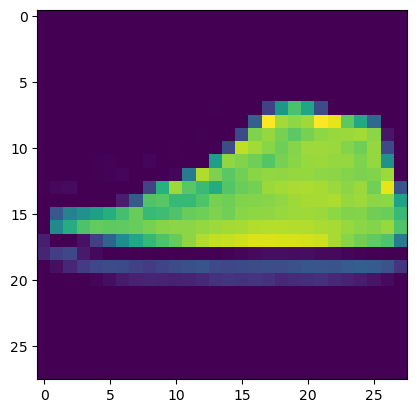

In [13]:
import matplotlib.pyplot as plt
plt.imshow(image_data)
plt.show()

In [14]:
import numpy as np
import cv2
import os

def load_mnist_dataset(dataset,path):
    labels = os.listdir(os.path.join(path,dataset))
    
    x = []
    y =[]
    
    for label in labels:
        for file in os.listdir(os.path.join(path,dataset,label)):
            
            image = cv2.imread(os.path.join(path,dataset,label,file),cv2.IMREAD_UNCHANGED)
            
            x.append(image)
            y.append(label)
            
    return np.array(x),np.array(y).astype("uint8")


def create_data_mnist(path):
    x,y = load_mnist_dataset("train",path)
    x_test,y_test = load_mnist_dataset("test",path)
    return x,y,x_test,y_test

In [15]:
x,y,x_test,y_test = create_data_mnist("fashion_mnist_images")
x = (x.astype(np.float32)-127.5)/127.5
x_test =(x_test.astype(np.float32)-127.5)/127.5


In [16]:
x=x.reshape(x.shape[0], -1)
x_test = x_test.reshape(x_test.shape[0],-1)

In [17]:
keys = np.array(range(x.shape[0]))
print(keys[:10])

import nnfs
nnfs.init()
np.random.shuffle(keys)
print(keys[:10])

x = x[keys]
y = y[keys]

[0 1 2 3 4 5 6 7 8 9]
[ 3048 19563 58303  8870 40228 31488 21860 56864   845 25770]


In [18]:
import nnfs
from nnfs.datasets import spiral_data

nnfs.init()

# x,y = spiral_data(samples=100,classes=3)
Epoches = 50
Batch_size = 32

steps = x.shape[0]//Batch_size
print(steps)

if steps*Batch_size<x.shape[0]:
    steps+=1
    
for epoch in range(Epoches):
    for step in range(steps):
        batch_x = x[step*Batch_size:(step+1)*Batch_size]
        batch_y = y[step*Batch_size:(step+1)*Batch_size]

1875


In [19]:
denselayer1 = Layer(784,128)
denselayer2 = Layer(128,128)
denselayer3 = Layer(128,128)
denselayer4 = Layer(128,10)
relu_activation1 = Activation_relu()
relu_activation2 = Activation_relu()
relu_activation3 = Activation_relu()
softmax_activation = activation_softmax()
loss_fun = Loss_CategoricalCrossentropy()
sgd_optimizer = optimizer_sgd()
adagrad_optimizer = optimizer_adagrad()
rmp_optimizer = Optimizer_RMSprop()
adam_optimizer = Optimizer_Adam()




In [20]:
# import cupy as cp
# print(cp.cuda.runtime.getDeviceCount())
# print(cp.cuda.runtime.getDeviceProperties(0)["name"])

In [21]:
# import cupy as cp
# np = cp

# import cupy as cp
# np = cp

# # convert existing data
# x = cp.asarray(x)
# y = cp.asarray(y)
# x_test = cp.asarray(x_test)
# y_test = cp.asarray(y_test)

# # re-create layers so weights/biases are generated with cp.random, not stale np arrays
# denselayer1 = Layer(784,128)
# denselayer2 = Layer(128,128)
# denselayer3 = Layer(128,128)
# denselayer4 = Layer(128,10)

In [22]:
# ============================================================
# Lens 2: Gradient Noise Scale
# Measures how noisy / inconsistent gradients are across samples
# ============================================================

def compute_gradient_noise_scale(batch_x, batch_y, layer1, layer2, layer3, layer4,
                                 relu_activation1, relu_activation2, relu_activation3,
                                 softmax_activation, loss_fun):
    
    per_sample_grads_l1 = []
    
    for i in range(batch_x.shape[0]):
        single_x = batch_x[i:i+1]
        single_y = batch_y[i:i+1]
        
        layer1.forward(single_x)
        relu_activation1.forward(layer1.outputs)
        layer2.forward(relu_activation1.outputs)
        relu_activation2.forward(layer2.outputs)
        layer3.forward(relu_activation2.outputs)
        relu_activation3.forward(layer3.outputs)
        layer4.forward(relu_activation3.outputs)
        softmax_activation.forward(layer4.outputs)
        
        loss_fun.backward(softmax_activation.outputs, single_y)
        softmax_activation.backward(loss_fun.dinputs)
        layer4.backward(softmax_activation.dinputs)
        relu_activation3.backward(layer4.dinputs)
        layer3.backward(relu_activation3.dinputs)
        relu_activation2.backward(layer3.dinputs)
        layer2.backward(relu_activation2.dinputs)
        relu_activation1.backward(layer2.dinputs)
        layer1.backward(relu_activation1.dinputs)
        
        per_sample_grads_l1.append(layer1.dweights.copy())
    
    per_sample_grads_l1 = np.array(per_sample_grads_l1)
    
    mean_grad = per_sample_grads_l1.mean(axis=0)
    variance = ((per_sample_grads_l1 - mean_grad) ** 2).mean(axis=0).sum()
    signal = (mean_grad ** 2).sum()
    noise_scale = variance / (signal + 1e-10)
    
    return noise_scale

In [23]:
eff_lr_history = []
noise_scale_history = []
Epoches = 50
Batch_size = 32
steps = x.shape[0] // Batch_size
if steps * Batch_size < x.shape[0]:
    steps += 1

for epoch in range(Epoches):
    epoch_loss = 0
    epoch_correct = 0
    for step in range(steps):
        batch_x = x[step*Batch_size:(step+1)*Batch_size]
        batch_y = y[step*Batch_size:(step+1)*Batch_size]

        denselayer1.forward(batch_x)
        relu_activation1.forward(denselayer1.outputs)
        denselayer2.forward(relu_activation1.outputs)
        relu_activation2.forward(denselayer2.outputs)
        denselayer3.forward(relu_activation2.outputs)
        relu_activation3.forward(denselayer3.outputs)
        denselayer4.forward(relu_activation3.outputs)
        softmax_activation.forward(denselayer4.outputs)

        loss = loss_fun.calculate(softmax_activation.outputs, batch_y)
        prediction = np.argmax(softmax_activation.outputs, axis=1)
        accuracy = np.mean(prediction == batch_y)
        epoch_loss += loss
        epoch_correct += accuracy

        loss_fun.backward(softmax_activation.outputs, batch_y)
        softmax_activation.backward(loss_fun.dinputs)
        denselayer4.backward(softmax_activation.dinputs)
        relu_activation3.backward(denselayer4.dinputs)
        denselayer3.backward(relu_activation3.dinputs)
        relu_activation2.backward(denselayer3.dinputs)
        denselayer2.backward(relu_activation2.dinputs)
        relu_activation1.backward(denselayer2.dinputs)
        denselayer1.backward(relu_activation1.dinputs)

        sgd_optimizer.pre_update_parameter()
        call_update(sgd_optimizer, denselayer1)
        call_update(sgd_optimizer, denselayer2)
        call_update(sgd_optimizer, denselayer3)
        call_update(sgd_optimizer, denselayer4)
        sgd_optimizer.post_update_parameters()

    print(f"Epoch: {epoch}, avg loss: {epoch_loss/steps:.3f}, avg acc: {epoch_correct/steps:.3f}")

    eff_lr_l1 = compute_effective_lr_matrix(sgd_optimizer, denselayer1)
    eff_lr_l2 = compute_effective_lr_matrix(sgd_optimizer, denselayer2)
    eff_lr_l3 = compute_effective_lr_matrix(sgd_optimizer, denselayer3)
    eff_lr_l4 = compute_effective_lr_matrix(sgd_optimizer, denselayer4)

    avg_eff_lr = np.mean([np.mean(eff_lr_l1), np.mean(eff_lr_l2), np.mean(eff_lr_l3), np.mean(eff_lr_l4)])
    eff_lr_history.append(avg_eff_lr)
    

    if epoch % 5 == 0:
        sample_batch_x = x[:32]
        sample_batch_y = y[:32]
        noise = compute_gradient_noise_scale(
            sample_batch_x, sample_batch_y,
            denselayer1, denselayer2, denselayer3, denselayer4,
            relu_activation1, relu_activation2, relu_activation3, softmax_activation, loss_fun
        )
        noise_scale_history.append(noise)
        
sgd_eff_lr_history = eff_lr_history

Epoch: 0, avg loss: 1.072, avg acc: 0.645
Epoch: 1, avg loss: 0.663, avg acc: 0.764
Epoch: 2, avg loss: 0.590, avg acc: 0.789
Epoch: 3, avg loss: 0.549, avg acc: 0.803
Epoch: 4, avg loss: 0.521, avg acc: 0.813
Epoch: 5, avg loss: 0.501, avg acc: 0.821
Epoch: 6, avg loss: 0.484, avg acc: 0.827
Epoch: 7, avg loss: 0.471, avg acc: 0.831
Epoch: 8, avg loss: 0.459, avg acc: 0.835
Epoch: 9, avg loss: 0.450, avg acc: 0.838
Epoch: 10, avg loss: 0.441, avg acc: 0.841
Epoch: 11, avg loss: 0.433, avg acc: 0.844
Epoch: 12, avg loss: 0.426, avg acc: 0.846
Epoch: 13, avg loss: 0.420, avg acc: 0.848
Epoch: 14, avg loss: 0.414, avg acc: 0.851
Epoch: 15, avg loss: 0.409, avg acc: 0.853
Epoch: 16, avg loss: 0.404, avg acc: 0.855
Epoch: 17, avg loss: 0.399, avg acc: 0.857
Epoch: 18, avg loss: 0.394, avg acc: 0.858
Epoch: 19, avg loss: 0.390, avg acc: 0.860
Epoch: 20, avg loss: 0.386, avg acc: 0.861
Epoch: 21, avg loss: 0.382, avg acc: 0.862
Epoch: 22, avg loss: 0.379, avg acc: 0.863
Epoch: 23, avg loss: 

In [24]:
denselayer1.forward(x_test)
relu_activation1.forward(denselayer1.outputs)
denselayer2.forward(relu_activation1.outputs)
relu_activation2.forward(denselayer2.outputs)
denselayer3.forward(relu_activation2.outputs)
relu_activation3.forward(denselayer3.outputs)
denselayer4.forward(relu_activation3.outputs)
softmax_activation.forward(denselayer4.outputs)
test_pred = np.argmax(softmax_activation.outputs, axis=1)
sgd_test_acc = np.mean(test_pred == y_test)
print("SGD test accuracy:", sgd_test_acc)

SGD test accuracy: 0.862


In [25]:


layers = [denselayer1, denselayer2, denselayer3, denselayer4]
w = get_flat_weights(layers)

sample_X = x[:64]
sample_y = y[:64]

v = np.random.randn(len(w))
v = v / np.linalg.norm(v)

for i in range(20):
    Hv = hessian_vector_product(w, v, layers, sample_X, sample_y)
    eigenvalue_estimate = np.linalg.norm(Hv)
    v = Hv / (eigenvalue_estimate + 1e-10)

sharpness = eigenvalue_estimate
sgd_noise_history = noise_scale_history      # (and adagrad_/rmp_/adam_ versions)
sgd_sharpness = sharpness                    # (and adagrad_/rmp_/adam_ versions)

set_flat_weights(layers, w)

In [26]:
denselayer1 = Layer(784,128)
denselayer2 = Layer(128,128)
denselayer3 = Layer(128,128)
denselayer4 = Layer(128,10)
relu_activation1 = Activation_relu()
relu_activation2 = Activation_relu()
relu_activation3 = Activation_relu()
softmax_activation = activation_softmax()
loss_fun = Loss_CategoricalCrossentropy()
sgd_optimizer = optimizer_sgd()
adagrad_optimizer = optimizer_adagrad()
rmp_optimizer = Optimizer_RMSprop()
adam_optimizer = Optimizer_Adam()




In [27]:
eff_lr_history = []
noise_scale_history = []
Epoches = 50
Batch_size = 32
steps = x.shape[0] // Batch_size
if steps * Batch_size < x.shape[0]:
    steps += 1

for epoch in range(Epoches):
    epoch_loss = 0
    epoch_correct = 0
    for step in range(steps):
        batch_x = x[step*Batch_size:(step+1)*Batch_size]
        batch_y = y[step*Batch_size:(step+1)*Batch_size]

        denselayer1.forward(batch_x)
        relu_activation1.forward(denselayer1.outputs)
        denselayer2.forward(relu_activation1.outputs)
        relu_activation2.forward(denselayer2.outputs)
        denselayer3.forward(relu_activation2.outputs)
        relu_activation3.forward(denselayer3.outputs)
        denselayer4.forward(relu_activation3.outputs)
        softmax_activation.forward(denselayer4.outputs)

        loss = loss_fun.calculate(softmax_activation.outputs, batch_y)
        prediction = np.argmax(softmax_activation.outputs, axis=1)
        accuracy = np.mean(prediction == batch_y)
        epoch_loss += loss
        epoch_correct += accuracy

        loss_fun.backward(softmax_activation.outputs, batch_y)
        softmax_activation.backward(loss_fun.dinputs)
        denselayer4.backward(softmax_activation.dinputs)
        relu_activation3.backward(denselayer4.dinputs)
        denselayer3.backward(relu_activation3.dinputs)
        relu_activation2.backward(denselayer3.dinputs)
        denselayer2.backward(relu_activation2.dinputs)
        relu_activation1.backward(denselayer2.dinputs)
        denselayer1.backward(relu_activation1.dinputs)

        adagrad_optimizer.pre_update_parameter()
        call_update(adagrad_optimizer, denselayer1)
        call_update(adagrad_optimizer, denselayer2)
        call_update(adagrad_optimizer, denselayer3)
        call_update(adagrad_optimizer, denselayer4)
        adagrad_optimizer.post_update_parameters()

    print(f"Epoch: {epoch}, avg loss: {epoch_loss/steps:.3f}, avg acc: {epoch_correct/steps:.3f}")

    eff_lr_l1 = compute_effective_lr_matrix(adagrad_optimizer, denselayer1)
    eff_lr_l2 = compute_effective_lr_matrix(adagrad_optimizer, denselayer2)
    eff_lr_l3 = compute_effective_lr_matrix(adagrad_optimizer, denselayer3)
    eff_lr_l4 = compute_effective_lr_matrix(adagrad_optimizer, denselayer4)
    avg_eff_lr = np.mean([np.mean(eff_lr_l1), np.mean(eff_lr_l2), np.mean(eff_lr_l3), np.mean(eff_lr_l4)])
    eff_lr_history.append(avg_eff_lr)

    if epoch % 5 == 0:
        sample_batch_x = x[:32]
        sample_batch_y = y[:32]
        noise = compute_gradient_noise_scale(
            sample_batch_x, sample_batch_y,
            denselayer1, denselayer2, denselayer3, denselayer4,
            relu_activation1, relu_activation2, relu_activation3, softmax_activation, loss_fun
        )
        noise_scale_history.append(noise)

adagrad_eff_lr_history = eff_lr_history

Epoch: 0, avg loss: 0.475, avg acc: 0.831
Epoch: 1, avg loss: 0.352, avg acc: 0.871
Epoch: 2, avg loss: 0.320, avg acc: 0.883
Epoch: 3, avg loss: 0.300, avg acc: 0.890
Epoch: 4, avg loss: 0.285, avg acc: 0.895
Epoch: 5, avg loss: 0.272, avg acc: 0.900
Epoch: 6, avg loss: 0.262, avg acc: 0.904
Epoch: 7, avg loss: 0.252, avg acc: 0.907
Epoch: 8, avg loss: 0.244, avg acc: 0.910
Epoch: 9, avg loss: 0.237, avg acc: 0.913
Epoch: 10, avg loss: 0.230, avg acc: 0.915
Epoch: 11, avg loss: 0.224, avg acc: 0.918
Epoch: 12, avg loss: 0.218, avg acc: 0.920
Epoch: 13, avg loss: 0.213, avg acc: 0.922
Epoch: 14, avg loss: 0.208, avg acc: 0.924
Epoch: 15, avg loss: 0.203, avg acc: 0.926
Epoch: 16, avg loss: 0.199, avg acc: 0.929
Epoch: 17, avg loss: 0.194, avg acc: 0.930
Epoch: 18, avg loss: 0.190, avg acc: 0.932
Epoch: 19, avg loss: 0.186, avg acc: 0.933
Epoch: 20, avg loss: 0.182, avg acc: 0.935
Epoch: 21, avg loss: 0.179, avg acc: 0.937
Epoch: 22, avg loss: 0.175, avg acc: 0.938
Epoch: 23, avg loss: 

In [28]:
denselayer1.forward(x_test)
relu_activation1.forward(denselayer1.outputs)
denselayer2.forward(relu_activation1.outputs)
relu_activation2.forward(denselayer2.outputs)
denselayer3.forward(relu_activation2.outputs)
relu_activation3.forward(denselayer3.outputs)
denselayer4.forward(relu_activation3.outputs)
softmax_activation.forward(denselayer4.outputs)
test_pred = np.argmax(softmax_activation.outputs, axis=1)
adagrad_test_acc = np.mean(test_pred == y_test)
print("Adagrad test accuracy:", adagrad_test_acc)

Adagrad test accuracy: 0.8847


In [29]:


layers = [denselayer1, denselayer2, denselayer3, denselayer4]
w = get_flat_weights(layers)

sample_X = x[:64]
sample_y = y[:64]

v = np.random.randn(len(w))
v = v / np.linalg.norm(v)

for i in range(20):
    Hv = hessian_vector_product(w, v, layers, sample_X, sample_y)
    eigenvalue_estimate = np.linalg.norm(Hv)
    v = Hv / (eigenvalue_estimate + 1e-10)

sharpness = eigenvalue_estimate
adagrad_noise_history = noise_scale_history      # (and adagrad_/rmp_/adam_ versions)
adagrad_sharpness = sharpness                     # (and adagrad_/rmp_/adam_ versions)

set_flat_weights(layers, w)

In [30]:
denselayer1 = Layer(784,128)
denselayer2 = Layer(128,128)
denselayer3 = Layer(128,128)
denselayer4 = Layer(128,10)
relu_activation1 = Activation_relu()
relu_activation2 = Activation_relu()
relu_activation3 = Activation_relu()
softmax_activation = activation_softmax()
loss_fun = Loss_CategoricalCrossentropy()
sgd_optimizer = optimizer_sgd()
adagrad_optimizer = optimizer_adagrad()
rmp_optimizer = Optimizer_RMSprop()
adam_optimizer = Optimizer_Adam()




In [31]:
eff_lr_history = []
noise_scale_history = []
Epoches = 50
Batch_size = 32
steps = x.shape[0] // Batch_size
if steps * Batch_size < x.shape[0]:
    steps += 1

for epoch in range(Epoches):
    epoch_loss = 0
    epoch_correct = 0
    for step in range(steps):
        batch_x = x[step*Batch_size:(step+1)*Batch_size]
        batch_y = y[step*Batch_size:(step+1)*Batch_size]

        denselayer1.forward(batch_x)
        relu_activation1.forward(denselayer1.outputs)
        denselayer2.forward(relu_activation1.outputs)
        relu_activation2.forward(denselayer2.outputs)
        denselayer3.forward(relu_activation2.outputs)
        relu_activation3.forward(denselayer3.outputs)
        denselayer4.forward(relu_activation3.outputs)
        softmax_activation.forward(denselayer4.outputs)

        loss = loss_fun.calculate(softmax_activation.outputs, batch_y)
        prediction = np.argmax(softmax_activation.outputs, axis=1)
        accuracy = np.mean(prediction == batch_y)
        epoch_loss += loss
        epoch_correct += accuracy

        loss_fun.backward(softmax_activation.outputs, batch_y)
        softmax_activation.backward(loss_fun.dinputs)
        denselayer4.backward(softmax_activation.dinputs)
        relu_activation3.backward(denselayer4.dinputs)
        denselayer3.backward(relu_activation3.dinputs)
        relu_activation2.backward(denselayer3.dinputs)
        denselayer2.backward(relu_activation2.dinputs)
        relu_activation1.backward(denselayer2.dinputs)
        denselayer1.backward(relu_activation1.dinputs)

        rmp_optimizer.pre_update_params()
        call_update(rmp_optimizer, denselayer1)
        call_update(rmp_optimizer, denselayer2)
        call_update(rmp_optimizer, denselayer3)
        call_update(rmp_optimizer, denselayer4)
        rmp_optimizer.post_update_params()

    print(f"Epoch: {epoch}, avg loss: {epoch_loss/steps:.3f}, avg acc: {epoch_correct/steps:.3f}")

    eff_lr_l1 = compute_effective_lr_matrix(rmp_optimizer, denselayer1)
    eff_lr_l2 = compute_effective_lr_matrix(rmp_optimizer, denselayer2)
    eff_lr_l3 = compute_effective_lr_matrix(rmp_optimizer, denselayer3)
    eff_lr_l4 = compute_effective_lr_matrix(rmp_optimizer, denselayer4)
    avg_eff_lr = np.mean([np.mean(eff_lr_l1), np.mean(eff_lr_l2), np.mean(eff_lr_l3), np.mean(eff_lr_l4)])
    eff_lr_history.append(avg_eff_lr)

    if epoch % 5 == 0:
        sample_batch_x = x[:32]
        sample_batch_y = y[:32]
        noise = compute_gradient_noise_scale(
            sample_batch_x, sample_batch_y,
            denselayer1, denselayer2, denselayer3, denselayer4,
            relu_activation1, relu_activation2, relu_activation3, softmax_activation, loss_fun
        )
        noise_scale_history.append(noise)

rmp_eff_lr_history = eff_lr_history


Epoch: 0, avg loss: 0.504, avg acc: 0.818
Epoch: 1, avg loss: 0.409, avg acc: 0.857
Epoch: 2, avg loss: 0.399, avg acc: 0.862
Epoch: 3, avg loss: 0.393, avg acc: 0.865
Epoch: 4, avg loss: 0.389, avg acc: 0.868
Epoch: 5, avg loss: 0.386, avg acc: 0.872
Epoch: 6, avg loss: 0.385, avg acc: 0.874
Epoch: 7, avg loss: 0.387, avg acc: 0.875
Epoch: 8, avg loss: 0.385, avg acc: 0.875
Epoch: 9, avg loss: 0.377, avg acc: 0.879
Epoch: 10, avg loss: 0.365, avg acc: 0.882
Epoch: 11, avg loss: 0.362, avg acc: 0.884
Epoch: 12, avg loss: 0.351, avg acc: 0.887
Epoch: 13, avg loss: 0.354, avg acc: 0.888
Epoch: 14, avg loss: 0.363, avg acc: 0.889
Epoch: 15, avg loss: 0.348, avg acc: 0.891
Epoch: 16, avg loss: 0.348, avg acc: 0.892
Epoch: 17, avg loss: 0.354, avg acc: 0.894
Epoch: 18, avg loss: 0.352, avg acc: 0.894
Epoch: 19, avg loss: 0.342, avg acc: 0.897
Epoch: 20, avg loss: 0.343, avg acc: 0.897
Epoch: 21, avg loss: 0.343, avg acc: 0.899
Epoch: 22, avg loss: 0.341, avg acc: 0.899
Epoch: 23, avg loss: 

In [32]:
denselayer1.forward(x_test)
relu_activation1.forward(denselayer1.outputs)
denselayer2.forward(relu_activation1.outputs)
relu_activation2.forward(denselayer2.outputs)
denselayer3.forward(relu_activation2.outputs)
relu_activation3.forward(denselayer3.outputs)
denselayer4.forward(relu_activation3.outputs)
softmax_activation.forward(denselayer4.outputs)
test_pred = np.argmax(softmax_activation.outputs, axis=1)
rmp_test_acc = np.mean(test_pred == y_test)
print("RMSprop test accuracy:", rmp_test_acc)

RMSprop test accuracy: 0.8511


In [33]:


layers = [denselayer1, denselayer2, denselayer3, denselayer4]
w = get_flat_weights(layers)

sample_X = x[:64]
sample_y = y[:64]

v = np.random.randn(len(w))
v = v / np.linalg.norm(v)

for i in range(20):
    Hv = hessian_vector_product(w, v, layers, sample_X, sample_y)
    eigenvalue_estimate = np.linalg.norm(Hv)
    v = Hv / (eigenvalue_estimate + 1e-10)

sharpness = eigenvalue_estimate
rmp_noise_history = noise_scale_history      # (and adagrad_/rmp_/adam_ versions)
rmp_sharpness = sharpness                     # (and adagrad_/rmp_/adam_ versions)
set_flat_weights(layers, w)

In [34]:
denselayer1 = Layer(784,128)
denselayer2 = Layer(128,128)
denselayer3 = Layer(128,128)
denselayer4 = Layer(128,10)
relu_activation1 = Activation_relu()
relu_activation2 = Activation_relu()
relu_activation3 = Activation_relu()
softmax_activation = activation_softmax()
loss_fun = Loss_CategoricalCrossentropy()
sgd_optimizer = optimizer_sgd()
adagrad_optimizer = optimizer_adagrad()
rmp_optimizer = Optimizer_RMSprop()
adam_optimizer = Optimizer_Adam()




In [35]:
eff_lr_history = []
noise_scale_history = []
Epoches = 50
Batch_size = 32
steps = x.shape[0] // Batch_size
if steps * Batch_size < x.shape[0]:
    steps += 1

for epoch in range(Epoches):
    epoch_loss = 0
    epoch_correct = 0
    for step in range(steps):
        batch_x = x[step*Batch_size:(step+1)*Batch_size]
        batch_y = y[step*Batch_size:(step+1)*Batch_size]

        denselayer1.forward(batch_x)
        relu_activation1.forward(denselayer1.outputs)
        denselayer2.forward(relu_activation1.outputs)
        relu_activation2.forward(denselayer2.outputs)
        denselayer3.forward(relu_activation2.outputs)
        relu_activation3.forward(denselayer3.outputs)
        denselayer4.forward(relu_activation3.outputs)
        softmax_activation.forward(denselayer4.outputs)

        loss = loss_fun.calculate(softmax_activation.outputs, batch_y)
        prediction = np.argmax(softmax_activation.outputs, axis=1)
        accuracy = np.mean(prediction == batch_y)
        epoch_loss += loss
        epoch_correct += accuracy

        loss_fun.backward(softmax_activation.outputs, batch_y)
        softmax_activation.backward(loss_fun.dinputs)
        denselayer4.backward(softmax_activation.dinputs)
        relu_activation3.backward(denselayer4.dinputs)
        denselayer3.backward(relu_activation3.dinputs)
        relu_activation2.backward(denselayer3.dinputs)
        denselayer2.backward(relu_activation2.dinputs)
        relu_activation1.backward(denselayer2.dinputs)
        denselayer1.backward(relu_activation1.dinputs)

        adam_optimizer.pre_update_params()
        call_update(adam_optimizer, denselayer1)
        call_update(adam_optimizer, denselayer2)
        call_update(adam_optimizer, denselayer3)
        call_update(adam_optimizer, denselayer4)
        adam_optimizer.post_update_params()

    print(f"Epoch: {epoch}, avg loss: {epoch_loss/steps:.3f}, avg acc: {epoch_correct/steps:.3f}")

    eff_lr_l1 = compute_effective_lr_matrix(adam_optimizer, denselayer1)
    eff_lr_l2 = compute_effective_lr_matrix(adam_optimizer, denselayer2)
    eff_lr_l3 = compute_effective_lr_matrix(adam_optimizer, denselayer3)
    eff_lr_l4 = compute_effective_lr_matrix(adam_optimizer, denselayer4)
    avg_eff_lr = np.mean([np.mean(eff_lr_l1), np.mean(eff_lr_l2), np.mean(eff_lr_l3), np.mean(eff_lr_l4)])
    eff_lr_history.append(avg_eff_lr)

    if epoch % 5 == 0:
        sample_batch_x = x[:32]
        sample_batch_y = y[:32]
        noise = compute_gradient_noise_scale(
            sample_batch_x, sample_batch_y,
            denselayer1, denselayer2, denselayer3, denselayer4,
            relu_activation1, relu_activation2, relu_activation3, softmax_activation, loss_fun
        )
        noise_scale_history.append(noise)

adam_eff_lr_history = eff_lr_history           

Epoch: 0, avg loss: 0.493, avg acc: 0.820
Epoch: 1, avg loss: 0.373, avg acc: 0.863
Epoch: 2, avg loss: 0.336, avg acc: 0.876
Epoch: 3, avg loss: 0.310, avg acc: 0.885
Epoch: 4, avg loss: 0.293, avg acc: 0.891
Epoch: 5, avg loss: 0.276, avg acc: 0.897
Epoch: 6, avg loss: 0.260, avg acc: 0.903
Epoch: 7, avg loss: 0.247, avg acc: 0.906
Epoch: 8, avg loss: 0.239, avg acc: 0.911
Epoch: 9, avg loss: 0.227, avg acc: 0.914
Epoch: 10, avg loss: 0.220, avg acc: 0.917
Epoch: 11, avg loss: 0.212, avg acc: 0.920
Epoch: 12, avg loss: 0.203, avg acc: 0.923
Epoch: 13, avg loss: 0.197, avg acc: 0.925
Epoch: 14, avg loss: 0.191, avg acc: 0.928
Epoch: 15, avg loss: 0.181, avg acc: 0.931
Epoch: 16, avg loss: 0.181, avg acc: 0.932
Epoch: 17, avg loss: 0.171, avg acc: 0.935
Epoch: 18, avg loss: 0.165, avg acc: 0.936
Epoch: 19, avg loss: 0.163, avg acc: 0.937
Epoch: 20, avg loss: 0.156, avg acc: 0.941
Epoch: 21, avg loss: 0.156, avg acc: 0.940
Epoch: 22, avg loss: 0.149, avg acc: 0.943
Epoch: 23, avg loss: 

In [36]:
denselayer1.forward(x_test)
relu_activation1.forward(denselayer1.outputs)
denselayer2.forward(relu_activation1.outputs)
relu_activation2.forward(denselayer2.outputs)
denselayer3.forward(relu_activation2.outputs)
relu_activation3.forward(denselayer3.outputs)
denselayer4.forward(relu_activation3.outputs)
softmax_activation.forward(denselayer4.outputs)
test_pred = np.argmax(softmax_activation.outputs, axis=1)
adam_test_acc = np.mean(test_pred == y_test)
print("Adam test accuracy:", adam_test_acc)

Adam test accuracy: 0.8783


In [37]:
layers = [denselayer1, denselayer2, denselayer3, denselayer4]
w = get_flat_weights(layers)

sample_X = x[:64]
sample_y = y[:64]

v = np.random.randn(len(w))
v = v / np.linalg.norm(v)

for i in range(20):
    Hv = hessian_vector_product(w, v, layers, sample_X, sample_y)
    eigenvalue_estimate = np.linalg.norm(Hv)
    v = Hv / (eigenvalue_estimate + 1e-10)

sharpness = eigenvalue_estimate
set_flat_weights(layers, w)
print("sharpness:", sharpness)
adam_noise_history = noise_scale_history      # (and adagrad_/rmp_/adam_ versions)
adam_sharpness = sharpness 

sharpness: 29.463537


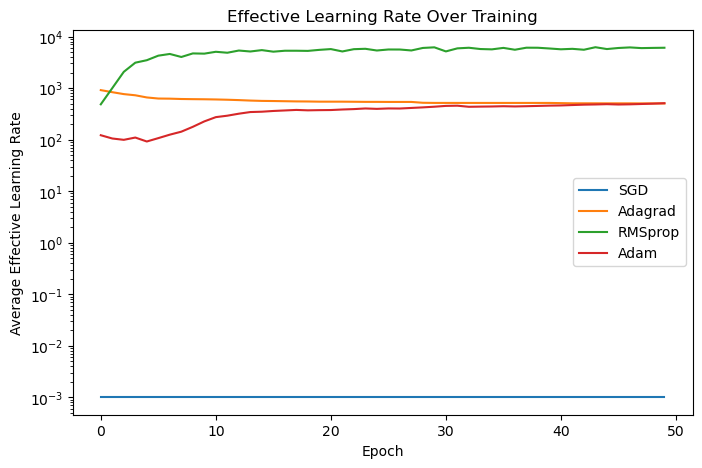

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.plot(sgd_eff_lr_history, label="SGD")
plt.plot(adagrad_eff_lr_history, label="Adagrad")
plt.plot(rmp_eff_lr_history, label="RMSprop")
plt.plot(adam_eff_lr_history, label="Adam")
plt.xlabel("Epoch")
plt.ylabel("Average Effective Learning Rate")
plt.title("Effective Learning Rate Over Training")
plt.legend()
plt.yscale("log")
plt.show()

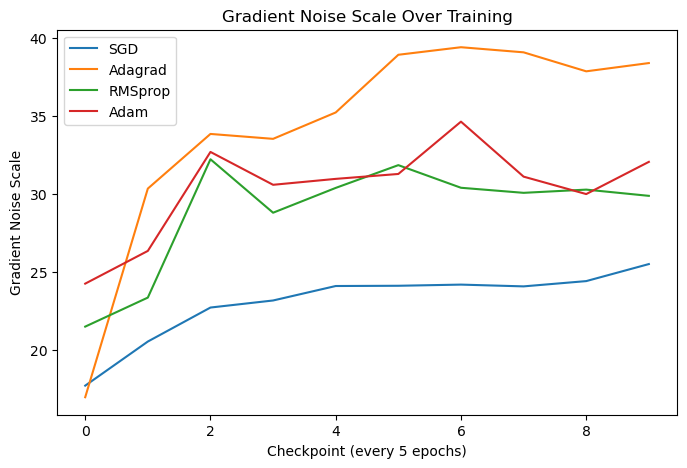

In [39]:
plt.figure(figsize=(8,5))
plt.plot(sgd_noise_history, label="SGD")
plt.plot(adagrad_noise_history, label="Adagrad")
plt.plot(rmp_noise_history, label="RMSprop")
plt.plot(adam_noise_history, label="Adam")
plt.xlabel("Checkpoint (every 5 epochs)")
plt.ylabel("Gradient Noise Scale")
plt.title("Gradient Noise Scale Over Training")
plt.legend()
plt.show()

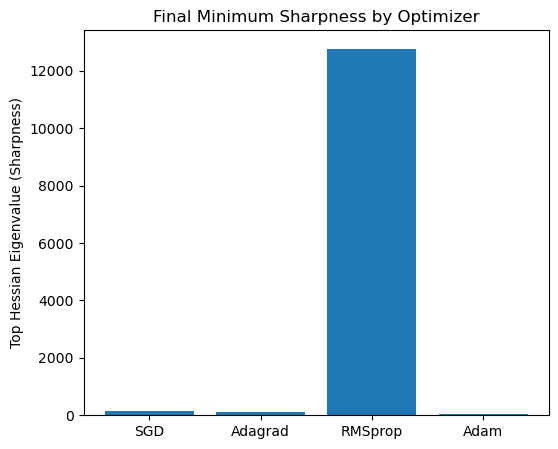

In [40]:
plt.figure(figsize=(6,5))
plt.bar(["SGD","Adagrad","RMSprop","Adam"],
        [sgd_sharpness, adagrad_sharpness, rmp_sharpness, adam_sharpness])
plt.ylabel("Top Hessian Eigenvalue (Sharpness)")
plt.title("Final Minimum Sharpness by Optimizer")
plt.show()

In [41]:
print(f"{'Optimizer':<10} {'Test Acc':<10} {'Sharpness':<12}")
print(f"{'SGD':<10} {sgd_test_acc:<10.3f} {sgd_sharpness:<12.3f}")
print(f"{'Adagrad':<10} {adagrad_test_acc:<10.3f} {adagrad_sharpness:<12.3f}")
print(f"{'RMSprop':<10} {rmp_test_acc:<10.3f} {rmp_sharpness:<12.3f}")
print(f"{'Adam':<10} {adam_test_acc:<10.3f} {adam_sharpness:<12.3f}")

Optimizer  Test Acc   Sharpness   
SGD        0.862      144.791     
Adagrad    0.885      123.874     
RMSprop    0.851      12770.637   
Adam       0.878      29.464      
